# Part 3.2: Daily activity-chain comparison

This notebook implements the agreed hierarchy: **chains containing an outside activity** versus **entirely within-area chains**, then eight chain types within the second group. One observation is one person's complete daily plan, not one trip, one home-based tour, or one distinct pattern. All residents aged 6+ remain in the main denominator, including stay-home residents. Mikrozensus uses person `WP`; MATSim uses unit weights. No simulation is run and no source data are modified.

“Outside” means outside the shared study boundary, not necessarily outside Switzerland. Survey endpoints identify spatial exits; MATSim outside/border labels additionally identify clipped or boundary-proxy activities whose stored coordinates may lie inside the polygon. These definitions are not perfectly interchangeable. Source CRS and the MATSim weekday remain unconfirmed, so results are preliminary.

In [1]:
from pathlib import Path
import os, tempfile, json, hashlib
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir())/'abmt_part3_mpl'))
os.environ.setdefault('XDG_CACHE_HOME', str(Path(tempfile.gettempdir())/'abmt_part3_cache'))
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from IPython.display import display, Markdown
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'microcensus_filter/microcensus_ne_weekday_persons.csv').exists()), None)
if ROOT is None: raise FileNotFoundError('Run from the project directory or a subdirectory.')
OUT = ROOT/'part3_results/tripchain'
OUT.mkdir(parents=True,exist_ok=True)
MP = ROOT/'microcensus_filter/microcensus_ne_weekday_persons.csv'
MT = ROOT/'microcensus_filter/microcensus_ne_weekday_trips.csv'
SP = ROOT/'simulation_filter/simulation_persons.csv'
SA = ROOT/'simulation_filter/simulation_activities.csv'
META = ROOT/'simulation_filter/preprocessing_metadata.json'
mp = pd.read_csv(MP,dtype=str,keep_default_na=False)
mt = pd.read_csv(MT,dtype=str,keep_default_na=False)
sp = pd.read_csv(SP,dtype=str,keep_default_na=False)
sa = pd.read_csv(SA,dtype=str,keep_default_na=False)
assert mp.HHNR.is_unique and sp.person.is_unique
assert pd.to_numeric(mp.tag).isin([1,2,3,4,5]).all()
original_sim_count = len(sp)
mp = mp.loc[pd.to_numeric(mp.alter).ge(6)].copy()
sp = sp.loc[pd.to_numeric(sp.age).ge(6)].copy()
mt = mt.loc[mt.HHNR.isin(mp.HHNR)].copy()
sa = sa.loc[sa.person.isin(sp.person) & sa.is_stage.str.lower().eq('false')].copy()
mp['weight'] = pd.to_numeric(mp.WP)
sp['weight'] = 1.0
assert mp.weight.gt(0).all() and np.isfinite(mp.weight).all()
AGE_LABELS = ['6–17','18–29','30–44','45–64','65+']
for frame,col in [(mp,'alter'),(sp,'age')]:
    frame['age_group_analysis'] = pd.cut(pd.to_numeric(frame[col]),[6,18,30,45,65,np.inf],labels=AGE_LABELS,right=False).astype(str)
metadata = json.loads(META.read_text())
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':120,'savefig.dpi':180})
COLORS = {'Mikrozensus':'#005F73','MATSim':'#CA6702'}
print(f'Eligible residents: Mikrozensus {len(mp):,}; MATSim {len(sp):,}.')
print('MATSim weekday verified:',metadata.get('weekday_filter_verified'),'| CRS verified:',metadata.get('crs_confirmed'))

Eligible residents: Mikrozensus 2,002; MATSim 16,972.
MATSim weekday verified: False | CRS verified: False


## 1. Verify survey purpose and home-return codes
The original codebook distinguishes `wzweck1` (purpose before the f52950 correction), `wzweck3` (purpose after that correction), and `wzweck2` (outbound / return-home / home-to-home). Use `wzweck3` as the corrected purpose and preserve both original purpose fields in the trip audit.

`wzweck2=2` means a home return even when purpose still says work or shopping; `wzweck2=3` is a home-to-home loop, not staying home. Such loops remain H→H and fall under Other chains, without inventing an unobserved intermediate stop. This also avoids inventing leisure activities for MATSim home-to-home legs. Retain loop-purpose codes in the audit.

Purpose groups: 2/6/7 → Work (including business/service travel), 3 → Education, 4 → Shopping, 8 → Leisure, 5/9/10/12 → Other. Codes 1 (transfer) and 13 (border crossing) are technical activities, not purposes. Negative codes are unknown. Code 11 is Home only with a home-return flag or a destination matching the primary home; otherwise its home/accommodation ambiguity is unresolved.

In [2]:
import zipfile
import xml.etree.ElementTree as ET
DICTIONARY = next((ROOT/'microcensus').glob('*.xlsx'))
def read_dictionary_sheet(path, sheet_name):
    ns = {'s': 'http://schemas.openxmlformats.org/spreadsheetml/2006/main'}
    with zipfile.ZipFile(path) as z:
        strings = []
        if 'xl/sharedStrings.xml' in z.namelist():
            sr = ET.fromstring(z.read('xl/sharedStrings.xml'))
            strings = [''.join(e.itertext()) for e in sr.findall('s:si', ns)]
        wb = ET.fromstring(z.read('xl/workbook.xml'))
        sheet = next(e for e in wb.findall('s:sheets/s:sheet', ns) if e.get('name') == sheet_name)
        rid = sheet.get('{http://schemas.openxmlformats.org/officeDocument/2006/relationships}id')
        rels = ET.fromstring(z.read('xl/_rels/workbook.xml.rels'))
        target = next(e.get('Target') for e in rels if e.get('Id') == rid)
        target = target.lstrip('/') if target.startswith('/') else 'xl/' + target
        root = ET.fromstring(z.read(target))
        rows = []
        for r in root.findall('s:sheetData/s:row', ns):
            values = []
            for c in r.findall('s:c', ns):
                v = c.find('s:v', ns)
                value = v.text if v is not None else ''
                if c.get('t') == 's': value = strings[int(value)]
                elif c.get('t') == 'inlineStr': value = ''.join(c.find('s:is', ns).itertext())
                if value: values.append(value)
            rows.append(values)
        return rows


rows = read_dictionary_sheet(DICTIONARY,'Wege')
evidence=[]
for label,wanted in [('ZWECK',{str(i) for i in range(1,14)}),('ZWECKB',{'1','2','3'})]:
    start=next(i for i,r in enumerate(rows) if r and r[0]==label and len(r)==3)
    found=set()
    for j,row in enumerate(rows[start:start+25]):
        values=row[1:] if j==0 else row
        if len(values)>=2 and values[0] in wanted:
            evidence.append({'codebook':label,'code':values[0],'meaning_original':values[1]});found.add(values[0])
        if found==wanted:break
    assert found==wanted
purpose_evidence=pd.DataFrame(evidence)
purpose_evidence.to_csv(OUT/'purpose_codebook_evidence.csv',index=False)
display(purpose_evidence)

,codebook,code,meaning_original
0,ZWECK,1,"Umsteigen, Verkehrsmittelwechsel, Auto abstellen"
1,ZWECK,2,Arbeiten
2,ZWECK,3,"Ausbildung, Schule"
3,ZWECK,4,Einkaufen
4,ZWECK,5,Besorgungen und Inanspruchnahme von Dienstleis...
5,ZWECK,6,Geschäftliche Tätigkeit
6,ZWECK,7,Dienstfahrt
7,ZWECK,8,Freizeitaktivität
8,ZWECK,9,Begleitweg (nur Kinder)
9,ZWECK,10,"Begleitweg/Serviceweg (Andere, z.B. Behinderte)"


## 2. Classify the geographical scope of each daily chain
Use `Boundary/neuchatel.shp`, including boundary points. Survey CH1903/LV03 coordinates are transformed from EPSG:21781. Foreign country codes (8100 is Switzerland) also establish an outside endpoint. Invalid or unresolved endpoints are not automatically treated as inside.

MATSim is outside if **any non-stage activity is labelled outside or border, OR has a valid coordinate outside the polygon**. The union prevents an external activity with an ordinary purpose from being incorrectly labelled entirely within-area. Report all components separately for comparison with the earlier outside-label-only diagnostic. Stage activities are excluded. This detects activity locations, not paths that temporarily cross the boundary between two inside activities.

In [3]:
boundary=gpd.read_file(ROOT/'Boundary/neuchatel.shp')
assert boundary.crs is not None and boundary.geometry.is_valid.all()
shape=boundary.geometry.union_all()
for side in ['S','Z']:
    x=pd.to_numeric(mt[f'{side}_X_CH1903'],errors='coerce');y=pd.to_numeric(mt[f'{side}_Y_CH1903'],errors='coerce')
    country=pd.to_numeric(mt[f'{side}_LND'],errors='coerce')
    foreign=country.between(8200,8999)
    valid=x.between(400000,900000)&y.between(0,400000)
    status=pd.Series('Unknown',index=mt.index)
    pts=gpd.GeoDataFrame(index=mt.index[valid],geometry=gpd.points_from_xy(x[valid],y[valid]),crs='EPSG:21781').to_crs(boundary.crs)
    status.loc[valid]=np.where(pts.geometry.intersects(shape),'Inside','Outside')
    status.loc[foreign]='Outside'
    mt[f'{side}_scope']=status
mt['outside_endpoint']=mt.S_scope.eq('Outside')|mt.Z_scope.eq('Outside')
mt['unknown_endpoint']=mt.S_scope.eq('Unknown')|mt.Z_scope.eq('Unknown')
mc_scope=mt.groupby('HHNR').agg(outside=('outside_endpoint','any'),unknown=('unknown_endpoint','any'))
mp=mp.join(mc_scope,on='HHNR')
mp[['outside','unknown']]=mp[['outside','unknown']].fillna(False).astype(bool)

x=pd.to_numeric(sa.x,errors='coerce');y=pd.to_numeric(sa.y,errors='coerce')
valid=x.between(2000000,3000000)&y.between(800000,1500000)
pts=gpd.GeoDataFrame(index=sa.index[valid],geometry=gpd.points_from_xy(x[valid],y[valid]),crs=metadata['assumed_source_crs']).to_crs(boundary.crs)
sa['coordinate_outside']=False
sa.loc[valid,'coordinate_outside']=~pts.geometry.intersects(shape)
sa['coordinate_unknown']=~valid
sa['outside_label']=sa.activity_type_raw.eq('outside')
sa['border_label']=sa.activity_type_raw.eq('border')
sa['outside']=sa.outside_label|sa.border_label|sa.coordinate_outside
sim_scope=sa.groupby('person').agg(outside=('outside','any'),unknown=('coordinate_unknown','any'),
    outside_label=('outside_label','any'),border_label=('border_label','any'),coordinate_outside=('coordinate_outside','any'))
sp=sp.join(sim_scope,on='person')
assert sp.outside.notna().all()
for df in [mp,sp]:
    df['scope']=np.select([df.outside,df.unknown],['Contains outside activity','Unknown geography'],default='Entirely within area')
print('MATSim scope audit:', {key:int(sp[key].sum()) for key in ['outside_label','border_label','coordinate_outside','outside']})

MATSim scope audit: {'outside_label': 3271, 'border_label': 254, 'coordinate_outside': 1276, 'outside': 3276}


## 3. Reconstruct daily chains and record quality flags
Survey trips are ordered by `WEGNR`. Confirm the initial origin against household coordinates using a 100 m tolerance (allowing small coordinate differences), or an explicit home-to-home flag. Do not assume everyone starts at home. Record the first-origin distance and tolerance sensitivity. Unknown initial activities, pseudo-trips, unexplained sequence gaps, overlapping times, unknown purposes and spatial discontinuities produce `Unknown / incomplete`, not Other chains.

For return-home or home-to-home flags, classify the destination as Home. A non-return destination within 100 m of home does not override a known work/education/etc. purpose. A code-11 destination requires home evidence. Keep repeated activities and intermediate home returns: H–W–H–W–H is complex, not simple.

MATSim uses selected-plan non-stage activities already extracted by preprocessing; secondary home/work/education labels are merged with their broad purposes, with raw chains retained. Unknown labels remain unknown. Home-only requires no travel; H–H with a trip remains travel. Incomplete chains remain distinguishable even when their geography is known.

In [4]:
HOME_TOLERANCE_M=100.0
CONTINUITY_TOLERANCE_M=100.0
PURPOSE={2:'Work',6:'Work',7:'Work',3:'Education',4:'Shopping',8:'Leisure',5:'Other',9:'Other',10:'Other',12:'Other'}
mt['trip_order']=pd.to_numeric(mt.WEGNR,errors='coerce')
assert mt.trip_order.notna().all() and not mt.duplicated(['HHNR','trip_order']).any()
mt=mt.sort_values(['HHNR','trip_order'])
mt=mt.merge(mp[['HHNR','hh_W_X_CH1903','hh_W_Y_CH1903']],on='HHNR',how='left',validate='many_to_one')
for side in ['S','Z']:
    mt[f'{side}_home_distance_m']=np.hypot(pd.to_numeric(mt[f'{side}_X_CH1903'],errors='coerce')-pd.to_numeric(mt.hh_W_X_CH1903,errors='coerce'),
                                        pd.to_numeric(mt[f'{side}_Y_CH1903'],errors='coerce')-pd.to_numeric(mt.hh_W_Y_CH1903,errors='coerce'))
mt['purpose_code']=pd.to_numeric(mt.wzweck3,errors='coerce')
mt['return_code']=pd.to_numeric(mt.wzweck2,errors='coerce')
mt['destination_type']=mt.purpose_code.map(PURPOSE).fillna('Unknown')
mt.loc[mt.purpose_code.isin([1,13]),'destination_type']='Technical'
mt.loc[mt.purpose_code.eq(11)&mt.Z_home_distance_m.le(HOME_TOLERANCE_M),'destination_type']='Home'
mt.loc[mt.return_code.isin([2,3]),'destination_type']='Home'
trip_groups={pid:g for pid,g in mt.groupby('HHNR',sort=False)}
mc_records=[]
for _,p in mp.iterrows():
    g=trip_groups.get(p.HHNR)
    issues=[];first_distance=np.nan;loops=0
    if g is None:
        chain=['Home'] if str(p.at_home_all_day).lower()=='true' else ['Unknown']
        if chain==['Unknown']:issues.append('No trips without confirmed stay-home status')
        ntrips=0
    else:
        ntrips=len(g);first=g.iloc[0];first_distance=first.S_home_distance_m
        initial='Home' if first_distance<=HOME_TOLERANCE_M or first.return_code==3 else 'Unknown'
        chain=[initial]+g.loc[g.destination_type.ne('Technical'),'destination_type'].tolist()
        if initial=='Unknown':issues.append('Initial activity not established as Home')
        if 'Unknown' in chain:issues.append('Unknown activity purpose')
        if pd.to_numeric(g.pseudo,errors='coerce').eq(2).any():issues.append('Pseudo-trip present')
        order=g.trip_order.to_numpy()
        if order[0]!=1 or (np.diff(order)!=1).any():issues.append('Trip sequence gap')
        dep=pd.to_numeric(g.f51100,errors='coerce').to_numpy();arr=pd.to_numeric(g.f51400,errors='coerce').to_numpy()
        if (~np.isfinite(dep)).any() or (~np.isfinite(arr)).any() or (dep<0).any() or (arr<dep).any() or (dep[1:]<arr[:-1]).any():issues.append('Invalid or overlapping trip times')
        if len(g)>1:
            gaps=np.hypot(pd.to_numeric(g.S_X_CH1903).to_numpy()[1:]-pd.to_numeric(g.Z_X_CH1903).to_numpy()[:-1],
                          pd.to_numeric(g.S_Y_CH1903).to_numpy()[1:]-pd.to_numeric(g.Z_Y_CH1903).to_numpy()[:-1])
            if (gaps>CONTINUITY_TOLERANCE_M).any():issues.append('Discontinuous trip endpoints')
        loops=int(g.return_code.eq(3).sum())
    mc_records.append(dict(person=p.HHNR,dataset='Mikrozensus',weight=p.weight,age_group=p.age_group_analysis,
        scope=p.scope,chain=' > '.join(chain),chain_raw=' > '.join(chain),n_trips=ntrips,
        home_only=ntrips==0 and chain==['Home'],issues='; '.join(dict.fromkeys(issues)),
        first_origin_home_distance_m=first_distance,home_to_home_loops=loops))

SIM_PURPOSE={'home':'Home','home_secondary':'Home','work':'Work','work_secondary':'Work','education':'Education',
    'education_secondary':'Education','shop':'Shopping','shopping':'Shopping','leisure':'Leisure','other':'Other',
    'outside':'Outside','border':'Border'}
sa['activity_order']=pd.to_numeric(sa.sequence)
sa=sa.sort_values(['person','activity_order'])
assert not sa.duplicated(['person','activity_order']).any()
activity_groups={pid:g for pid,g in sa.groupby('person',sort=False)}
sim_records=[]
for _,p in sp.iterrows():
    g=activity_groups[p.person];chain=[SIM_PURPOSE.get(v,'Unknown') for v in g.activity_type_raw]
    ntrips=int(p.trip_count);issues=[]
    if 'Unknown' in chain:issues.append('Unknown activity purpose')
    if not chain:issues.append('Missing selected-plan activities')
    if p.day_status=='unknown / check':issues.append('Unresolved day status')
    sim_records.append(dict(person=p.person,dataset='MATSim',weight=1.,age_group=p.age_group_analysis,scope=p.scope,
        chain=' > '.join(chain),chain_raw=' > '.join(g.activity_type_raw),n_trips=ntrips,
        home_only=str(p.at_home_all_day).lower()=='true',issues='; '.join(issues),
        first_origin_home_distance_m=np.nan,home_to_home_loops=np.nan))
chains=pd.concat([pd.DataFrame(mc_records),pd.DataFrame(sim_records)],ignore_index=True)
assert not chains.duplicated(['dataset','person']).any()
assert chains.groupby('dataset').size().to_dict()=={'MATSim':len(sp),'Mikrozensus':len(mp)}
assert int(chains.loc[chains.dataset.eq('Mikrozensus'),'n_trips'].sum())==len(mt)
print('Survey first origins within home tolerance:',{t:int(pd.DataFrame(mc_records).first_origin_home_distance_m.le(t).sum()) for t in [10,50,100,200]})
print('Chains with a quality flag:')
print(chains.assign(flag=chains.issues.ne('')).groupby('dataset').flag.sum().to_string())

Survey first origins within home tolerance: {10: 1744, 50: 1744, 100: 1744, 200: 1745}
Chains with a quality flag:
dataset
MATSim          0
Mikrozensus    98


## 4. Apply the agreed eight within-area chain types

| Type | Exact rule / example |
|---|---|
| Home only | H with no trips |
| Simple work chain | Exactly H–W–H |
| Simple education chain | Exactly H–E–H |
| Simple shopping chain | Exactly H–S–H |
| Simple leisure chain | Exactly H–L–H |
| Complex work/education chain | At least two non-home activities and at least one Work/Education activity; e.g. H–W–S–H or H–W–H–W–H |
| Complex shopping/leisure chain | At least two non-home activities, including Shopping or Leisure, with no Work/Education; e.g. H–S–L–H, H–L–H–L–H or H–Other–S–H |
| Other chains | Remaining known patterns, including H–Other–H and travelling H–H loops |

`Unknown / incomplete` is an additional quality category, not a ninth behavioral type. Do not distribute these records across known types. A known, open-ended chain does not automatically become simple: only exact H–purpose–H matches qualify. The boundary hierarchy is applied before the eight-type breakdown.

In [5]:
CHAIN_TYPES=['Home only','Simple work chain','Simple education chain','Simple shopping chain','Simple leisure chain',
             'Complex work/education chain','Complex shopping/leisure chain','Other chains','Unknown / incomplete']
SCOPES=['Contains outside activity','Entirely within area','Unknown geography']
def classify(row):
    if row.scope!='Entirely within area':return 'Not subdivided'
    if row.issues:return 'Unknown / incomplete'
    seq=row.chain.split(' > ')
    if row.home_only:return 'Home only'
    for purpose,label in [('Work','Simple work chain'),('Education','Simple education chain'),('Shopping','Simple shopping chain'),('Leisure','Simple leisure chain')]:
        if seq==['Home',purpose,'Home']:return label
    nonhome=[v for v in seq if v!='Home']
    if len(nonhome)>=2 and any(v in ['Work','Education'] for v in nonhome):return 'Complex work/education chain'
    if len(nonhome)>=2 and not any(v in ['Work','Education'] for v in nonhome) and any(v in ['Shopping','Leisure'] for v in nonhome):return 'Complex shopping/leisure chain'
    return 'Other chains'
chains['chain_type']=chains.apply(classify,axis=1)
within=chains.loc[chains.scope.eq('Entirely within area')].copy()
assert within.chain_type.isin(CHAIN_TYPES).all()
assert within.loc[within.chain_type.eq('Home only'),'n_trips'].eq(0).all()
assert within.loc[within.issues.ne(''),'chain_type'].eq('Unknown / incomplete').all()
chains.to_csv(OUT/'person_daily_chain_classification.csv',index=False)
chains.loc[chains.issues.ne('')|chains.scope.eq('Unknown geography')].to_csv(OUT/'chain_review_cases.csv',index=False)
mt.to_csv(OUT/'microcensus_trip_reconstruction_audit.csv',index=False)
sp[['person','outside_label','border_label','coordinate_outside','outside','unknown','scope']].to_csv(OUT/'matsim_scope_audit.csv',index=False)

## 5. Aggregate and age-group comparisons
Top-level shares use **all eligible daily chains** as the denominator. Within-area shares use **all entirely within-area daily chains**, including Home only and Unknown / incomplete. Age-specific shares use the within-area population of each age group separately. Show raw sample counts alongside weighted shares; survey WP sums are not interpreted as cantonal population totals.

In [6]:
def distribution(data,field,categories):
    rows=[]
    for name in ['Mikrozensus','MATSim']:
        df=data.loc[data.dataset.eq(name)];total=df.weight.sum()
        for category in categories:
            part=df.loc[df[field].eq(category)]
            rows.append(dict(dataset=name,category=category,sample_n=len(part),weight_sum=part.weight.sum(),
                denominator_n=len(df),denominator_weight=total,share_pct=100*part.weight.sum()/total if total else np.nan))
    result=pd.DataFrame(rows)
    for name,g in result.groupby('dataset'):
        if g.denominator_n.iloc[0]:assert np.isclose(g.share_pct.sum(),100) and g.sample_n.sum()==g.denominator_n.iloc[0]
    return result

def comparison_table(table):
    a=table.loc[table.dataset.eq('Mikrozensus')].set_index('category').drop(columns='dataset').add_prefix('mc_')
    b=table.loc[table.dataset.eq('MATSim')].set_index('category').drop(columns='dataset').add_prefix('sim_')
    out=a.join(b);out['difference_pp']=out.sim_share_pct-out.mc_share_pct
    return out.reset_index()

top=distribution(chains,'scope',SCOPES)
inside=distribution(within,'chain_type',CHAIN_TYPES)
top_comparison=comparison_table(top);inside_comparison=comparison_table(inside)
age_tables=[]
for age in AGE_LABELS:
    table=distribution(within.loc[within.age_group.eq(age)],'chain_type',CHAIN_TYPES)
    table['age_group']=age;age_tables.append(table)
age_table=pd.concat(age_tables,ignore_index=True)
for name,frame in [('scope_shares',top),('within_area_chain_shares',inside),('scope_comparison',top_comparison),
                   ('within_area_chain_comparison',inside_comparison),('within_area_chain_shares_by_age',age_table)]:
    frame.to_csv(OUT/f'{name}.csv',index=False)
print('Top-level distribution:')
display(top_comparison[['category','mc_sample_n','sim_sample_n','mc_share_pct','sim_share_pct','difference_pp']].round(2))
print('Within-area daily-chain types:')
display(inside_comparison[['category','mc_sample_n','sim_sample_n','mc_share_pct','sim_share_pct','difference_pp']].round(2))
# Provide detailed patterns so Other chains can be inspected without guessing.
patterns=within.groupby(['dataset','chain_type','chain'],dropna=False).agg(sample_n=('person','size'),weight_sum=('weight','sum')).reset_index()
patterns=patterns.sort_values(['dataset','chain_type','weight_sum'],ascending=[True,True,False])
patterns.to_csv(OUT/'within_area_detailed_patterns.csv',index=False)
display(patterns.loc[patterns.chain_type.eq('Other chains')].groupby('dataset').head(8))

,category,mc_sample_n,sim_sample_n,mc_share_pct,sim_share_pct,difference_pp
0,Contains outside activity,323,3276,17.29,19.3,2.01
1,Entirely within area,1679,13696,82.71,80.7,-2.01
2,Unknown geography,0,0,0.00,0.0,0.00


,category,mc_sample_n,sim_sample_n,mc_share_pct,sim_share_pct,difference_pp
0,Home only,170,1651,10.20,12.05,1.86
1,Simple work chain,92,972,6.06,7.10,1.04
2,Simple education chain,24,275,1.18,2.01,0.83
3,Simple shopping chain,108,819,6.85,5.98,-0.87
4,Simple leisure chain,78,727,4.63,5.31,0.68
5,Complex work/education chain,700,5195,41.28,37.93,-3.35
6,Complex shopping/leisure chain,329,2860,19.16,20.88,1.72
7,Other chains,154,1197,8.98,8.74,-0.24
8,Unknown / incomplete,24,0,1.67,0.00,-1.67


,dataset,chain_type,chain,sample_n,weight_sum
1244,MATSim,Other chains,Home > Home,261,261.000000
1269,MATSim,Other chains,Home > Other > Home,209,209.000000
1279,MATSim,Other chains,Home > Shopping > Home > Home,138,138.000000
1245,MATSim,Other chains,Home > Home > Home,86,86.000000
1282,MATSim,Other chains,Home > Work > Home > Home,77,77.000000
1261,MATSim,Other chains,Home > Home > Shopping > Home,47,47.000000
1253,MATSim,Other chains,Home > Home > Leisure > Home,43,43.000000
1242,MATSim,Other chains,Home > Education > Home > Home,37,37.000000
1813,Mikrozensus,Other chains,Home > Home,44,18.072107
1832,Mikrozensus,Other chains,Home > Other > Home,34,14.423234


Top-level distribution:
Within-area daily-chain types:


## 6. Visualizations
Use the Ocean Sunset palette: Mikrozensus deep teal `#005F73`, MATSim ochre `#CA6702`. Zero-count unknown geography is omitted from the top-level chart only, not the tables. Unknown / incomplete chain quality remains in the within-area charts and denominators. The age heatmap shows MATSim minus survey shares within each age-specific within-area sample; it is not a significance test.

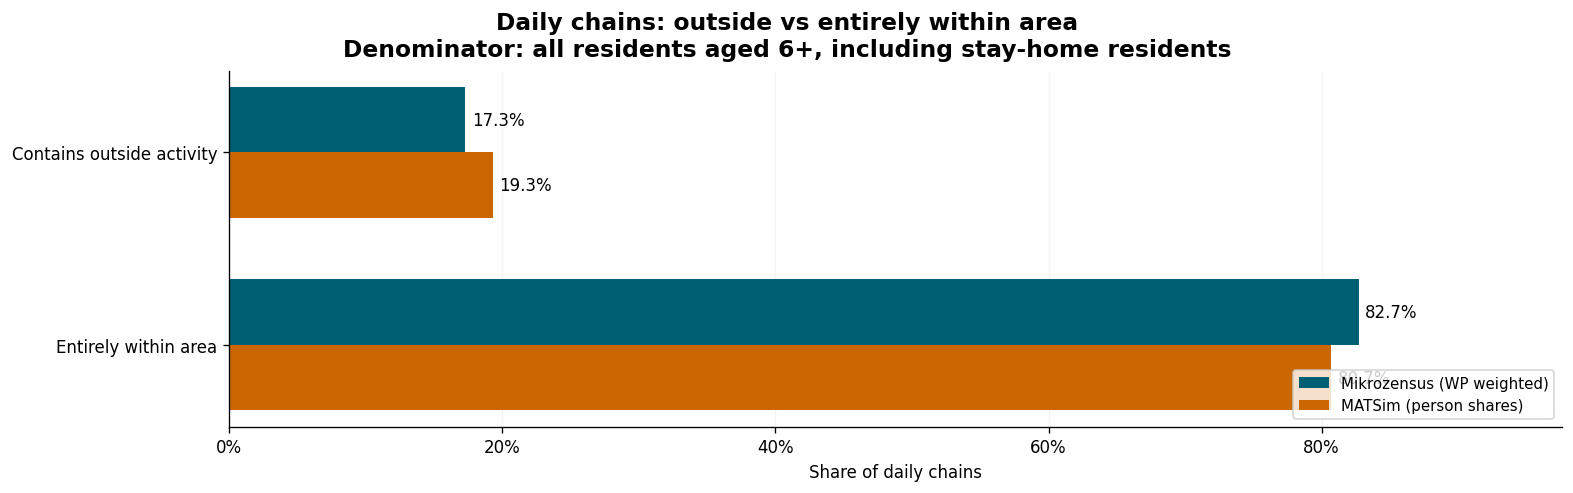

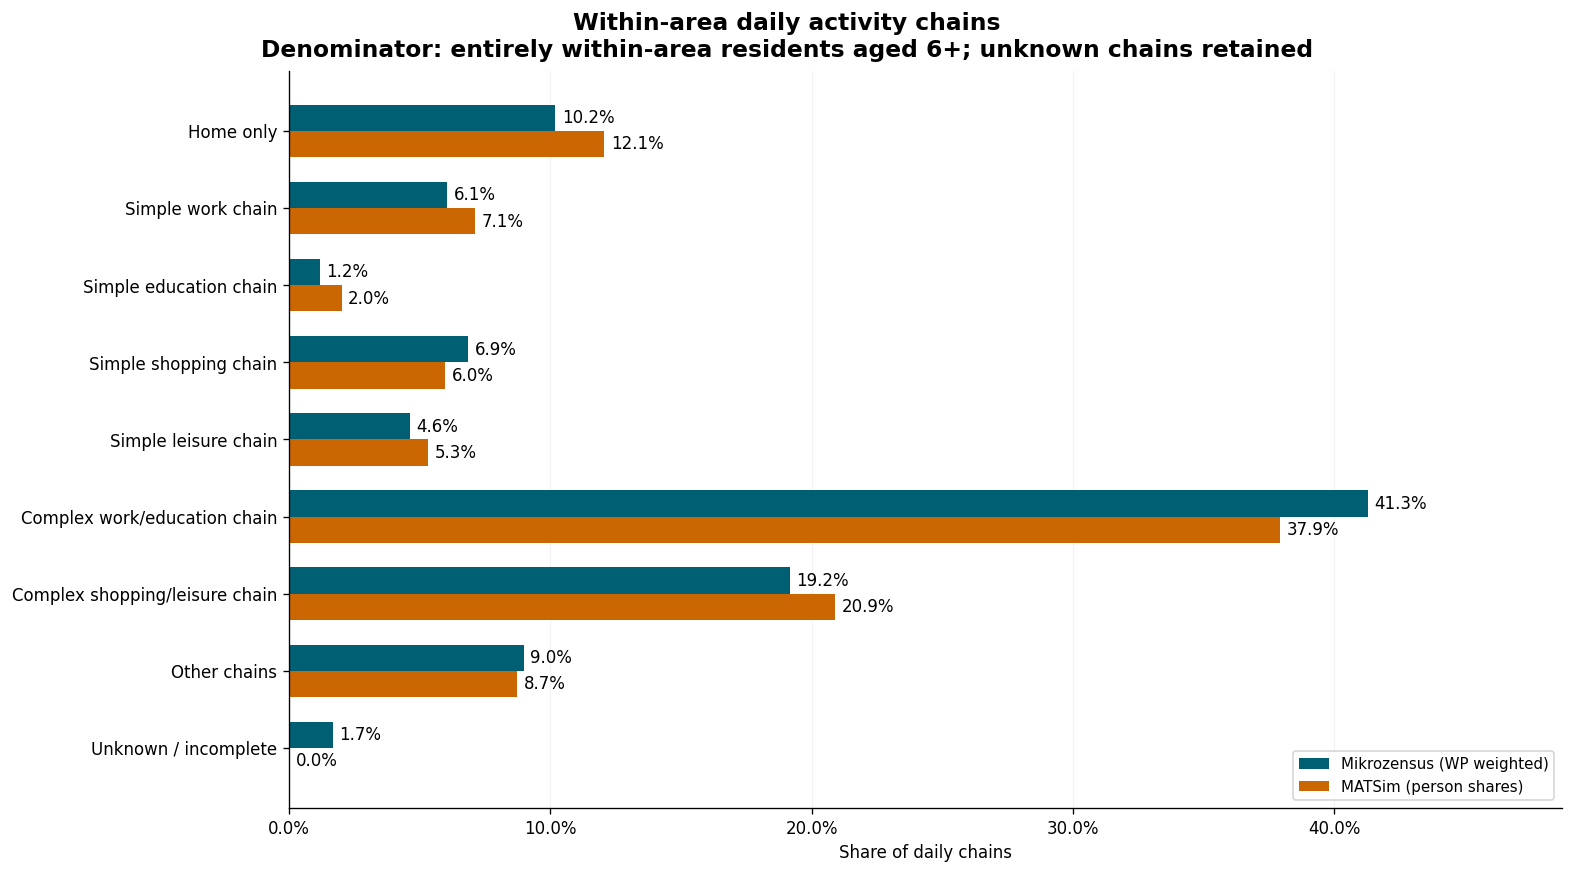

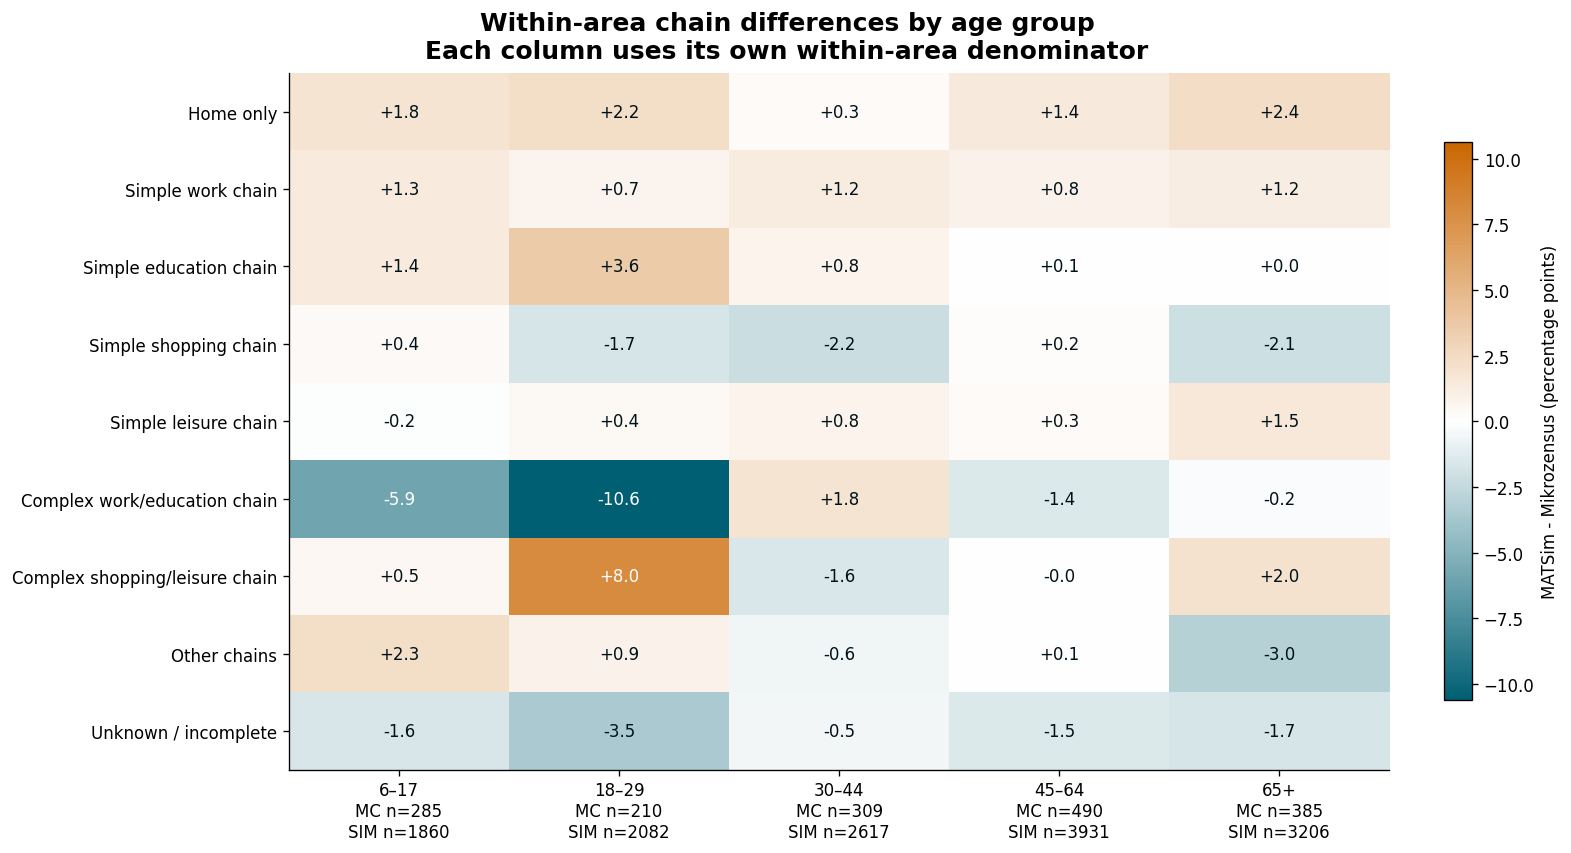

In [7]:
def paired_plot(table,title,subtitle,filename):
    cats=table.category.drop_duplicates().tolist()
    fig,ax=plt.subplots(figsize=(13,max(4,len(cats)*.63+1.5)),layout='constrained')
    y=np.arange(len(cats));h=.34
    for offset,name in [(-h/2,'Mikrozensus'),(h/2,'MATSim')]:
        d=table.loc[table.dataset.eq(name)].set_index('category').reindex(cats)
        bars=ax.barh(y+offset,d.share_pct,h,color=COLORS[name],label=name+(' (WP weighted)' if name=='Mikrozensus' else ' (person shares)'))
        ax.bar_label(bars,fmt='%.1f%%',padding=4,fontsize=10)
    ax.set(yticks=y,yticklabels=cats,xlabel='Share of daily chains',xlim=(0,min(115,max(15,table.share_pct.max()*1.18))))
    ax.invert_yaxis();ax.xaxis.set_major_formatter(PercentFormatter(100));ax.grid(axis='x',alpha=.15);ax.set_axisbelow(True)
    ax.legend(loc='lower right',fontsize=9)
    fig.suptitle(title+'\n'+subtitle,fontsize=14,fontweight='bold')
    fig.savefig(OUT/f'{filename}.png',bbox_inches='tight');fig.savefig(OUT/f'{filename}.pdf',bbox_inches='tight')
    display(fig);plt.close(fig)
shown=top.loc[top.category.ne('Unknown geography')] if top.loc[top.category.eq('Unknown geography'),'sample_n'].sum()==0 else top
paired_plot(shown,'Daily chains: outside vs entirely within area','Denominator: all residents aged 6+, including stay-home residents','01_scope_comparison')
paired_plot(inside,'Within-area daily activity chains','Denominator: entirely within-area residents aged 6+; unknown chains retained','02_within_area_chain_types')

age_differences=[]
for age in AGE_LABELS:
    d=comparison_table(age_table.loc[age_table.age_group.eq(age)])
    d['age_group']=age;age_differences.append(d)
age_diff=pd.concat(age_differences,ignore_index=True)
age_diff.to_csv(OUT/'within_area_chain_difference_by_age.csv',index=False)
matrix=age_diff.pivot(index='category',columns='age_group',values='difference_pp').reindex(index=CHAIN_TYPES,columns=AGE_LABELS)
limit=max(1,np.nanmax(np.abs(matrix.to_numpy())))
cmap=LinearSegmentedColormap.from_list('OceanSunsetDifference',['#005F73','#FFFFFF','#CA6702'])
fig,ax=plt.subplots(figsize=(13,7),layout='constrained')
im=ax.imshow(matrix.to_numpy(),cmap=cmap,norm=TwoSlopeNorm(vmin=-limit,vcenter=0,vmax=limit),aspect='auto')
labels=[]
for age in AGE_LABELS:
    counts=within.loc[within.age_group.eq(age)].dataset.value_counts()
    labels.append(f'{age}\nMC n={counts.get("Mikrozensus",0)}\nSIM n={counts.get("MATSim",0)}')
ax.set(xticks=np.arange(len(AGE_LABELS)),xticklabels=labels,yticks=np.arange(len(CHAIN_TYPES)),yticklabels=CHAIN_TYPES)
for i in range(len(CHAIN_TYPES)):
    for j in range(len(AGE_LABELS)):
        value=matrix.iloc[i,j]
        ax.text(j,i,f'{value:+.1f}' if np.isfinite(value) else 'N/A',ha='center',va='center',color='white' if abs(value)>limit*.55 else '#001219')
fig.colorbar(im,ax=ax,label='MATSim - Mikrozensus (percentage points)',shrink=.8)
fig.suptitle('Within-area chain differences by age group\nEach column uses its own within-area denominator',fontsize=15,fontweight='bold')
fig.savefig(OUT/'03_chain_differences_by_age.png',bbox_inches='tight');fig.savefig(OUT/'03_chain_differences_by_age.pdf',bbox_inches='tight')
display(fig);plt.close(fig)

## 7. Validation and provenance
All two-level counts must reconcile. Small synthetic checks protect the distinction between staying home and travelling home-to-home, exact simple chains, complex chains and unknown data. No p-values or claims of behavioral causality are produced. Geographic classification and purpose reconstruction are audited separately.

In [8]:
def example(seq,trips,issues='',scope='Entirely within area'):
    return pd.Series({'chain':seq,'n_trips':trips,'home_only':seq=='Home' and trips==0,'issues':issues,'scope':scope})
assert classify(example('Home',0))=='Home only'
assert classify(example('Home > Home',1))=='Other chains'
assert classify(example('Home > Work > Home',2))=='Simple work chain'
assert classify(example('Home > Work > Home > Work > Home',4))=='Complex work/education chain'
assert classify(example('Home > Shopping > Leisure > Home',3))=='Complex shopping/leisure chain'
assert classify(example('Home > Leisure > Home > Leisure > Home',4))=='Complex shopping/leisure chain'
assert classify(example('Home > Other > Shopping > Home',3))=='Complex shopping/leisure chain'
assert classify(example('Home > Work > Shopping > Leisure > Home',4))=='Complex work/education chain'
assert classify(example('Home > Shopping > Home',2))=='Simple shopping chain'
assert classify(example('Home > Unknown > Home',2,issues='Unknown purpose'))=='Unknown / incomplete'
assert classify(example('Home > Outside > Home',2,scope='Contains outside activity'))=='Not subdivided'
for name,frame in chains.groupby('dataset'):
    expected=len(mp) if name=='Mikrozensus' else len(sp)
    assert len(frame)==expected
    assert frame.scope.isin(SCOPES).all()
    assert (frame.scope.eq('Entirely within area')==frame.chain_type.isin(CHAIN_TYPES)).all()
assert len(pd.read_csv(SP))==original_sim_count
assert len(pd.read_csv(OUT/'person_daily_chain_classification.csv'))==len(mp)+len(sp)
def sha256(path):
    h=hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda:f.read(1024*1024),b''):h.update(block)
    return h.hexdigest()
provenance={'inputs':{str(p.relative_to(ROOT)):sha256(p) for p in [MP,MT,SP,SA,META,DICTIONARY]},
    'minimum_age':6,'unit':'one person-day','weights':{'Mikrozensus':'WP','MATSim':1},
    'survey_purpose_field':'wzweck3','return_field':'wzweck2','home_tolerance_m':HOME_TOLERANCE_M,
    'continuity_tolerance_m':CONTINUITY_TOLERANCE_M,'matsim_outside_rule':'outside label OR border label OR non-stage activity coordinate outside shared boundary',
    'home_to_home_loops':'Retain H-H; do not invent a destination activity; not Home only',
    'source_metadata':metadata,'unknown_handling':'Retain in denominator and report separately',
    'within_area_categories':CHAIN_TYPES,'scope_categories':SCOPES}
(OUT/'analysis_metadata.json').write_text(json.dumps(provenance,indent=2,ensure_ascii=False),encoding='utf-8')
print('Classification checks, denominator reconciliation and export validation passed.')

outer=top_comparison.set_index('category').loc['Contains outside activity']
known=inside_comparison.loc[inside_comparison.category.ne('Unknown / incomplete')]
largest=known.loc[known.difference_pp.abs().idxmax()]
unknown=inside_comparison.set_index('category').loc['Unknown / incomplete']
text=f"""- Outside-containing chains: **{outer.mc_share_pct:.2f}%** of Mikrozensus person-days and **{outer.sim_share_pct:.2f}%** of MATSim person-days, using the documented spatial/proxy rules.
- Within-area chains: the largest known-category gap is **{largest.category}** ({largest.mc_share_pct:.2f}% survey vs {largest.sim_share_pct:.2f}% MATSim; {largest.difference_pp:+.2f} percentage points).
- Unknown / incomplete chains remain **{unknown.mc_share_pct:.2f}%** of the within-area survey denominator and **{unknown.sim_share_pct:.2f}%** of the MATSim denominator.
- Results are descriptive and provisional; clipped outside locations, survey reconstruction and unconfirmed scenario metadata limit direct behavioral interpretation."""
(OUT/'takeaway.md').write_text('# takeaway\n\n'+text,encoding='utf-8')

Classification checks, denominator reconciliation and export validation passed.


## takeaway

- Outside-containing chains: **17.29%** of Mikrozensus person-days and **19.30%** of MATSim person-days, using the documented spatial/proxy rules.
- Within-area chains: the largest known-category gap is **Complex work/education chain** (41.28% survey vs 37.93% MATSim; -3.35 percentage points).
- Unknown / incomplete chains remain **1.67%** of the within-area survey denominator and **0.00%** of the MATSim denominator.
- Results are descriptive and provisional; clipped outside locations, survey reconstruction and unconfirmed scenario metadata limit direct behavioral interpretation.